In [26]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-26


# Cas de référence : échantillon monolithique

Noms des campagnes : 
- `campagne_honey`
- `campagne_honey_CC`
- `campagne_honey_UR3_S13`
- `campagne_honey_UR3_S7`

## Mapping sans CC en fct de theta et la taille du motif

Lecture des données réalisée en 1.72279s
300979
149887


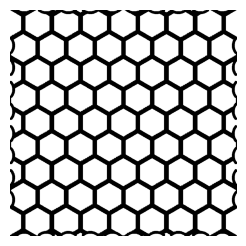

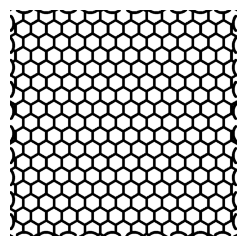

In [27]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

campagnes = ['campagne_honey']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

tmp = data['honey_13_0_0_0']
tmp.show_geo()

tmp = data['honey_7_0_0_0']
tmp.show_geo()


On commence ici par regarder l'influence du placement et de la taille du motif dans la machine.

honey_10_0_0_0 error : 1.56
302104


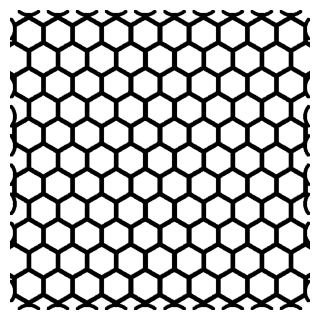

honey_10_0_6_6 error : 1.55
264895


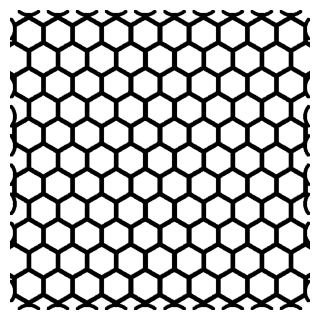

honey_10_1_6_6 error : 6.52
275474


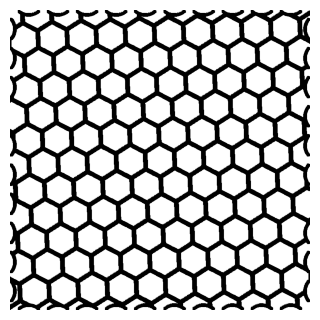

honey_13_0_6_3 error : 3.28
68271


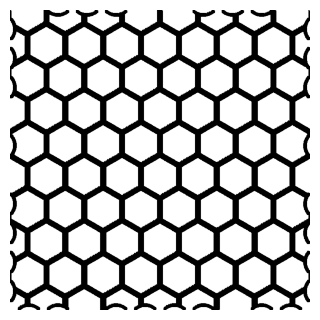

honey_7_0_6_6 error : 3.02
40785


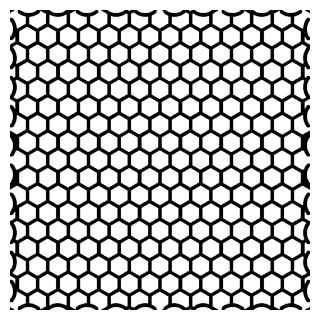

In [28]:
names=['honey_10_0_0_0', 'honey_10_0_6_6', 'honey_10_1_6_6','honey_13_0_6_3','honey_7_0_6_6',]

for name in names:
    print(f'{name} error : {data[name].get_error((0,3)):.2f}')
    data[name].show_geo()
    plt.subplots_adjust(top=1.0,bottom=0.0,left=0.0,right=1.0,hspace=0.2,wspace=0.25)
    plt.savefig(f'images/{name}.jpg', pil_kwargs={'quality': 60})
    plt.show()

# bests = get_best_test(data, (0,3), 10)
# for test in bests:
#     print(f'{test.test_id} error : {test.get_error((0,3)):.2f}')
#     test.show_geo()
#     plt.subplots_adjust(top=1.0,bottom=0.0,left=0.0,right=1.0,hspace=0.2,wspace=0.25)
#     plt.savefig(f'images/best/{test.test_id}_{test.get_error((0,3)):.2f}.jpg', pil_kwargs={'quality': 60})
#     plt.show()

# worse = get_worse_test(data, (0,3), 10)
# for test in worse:
#     print(f'{test.test_id} error : {test.get_error((0,3)):.2f}')
#     test.show_geo()
#     plt.subplots_adjust(top=1.0,bottom=0.0,left=0.0,right=1.0,hspace=0.2,wspace=0.25)
#     plt.savefig(f'images/worse/{test.test_id}_{test.get_error((0,3)):.2f}.jpg', pil_kwargs={'quality': 60})
#     plt.show()

2.1269820573204843


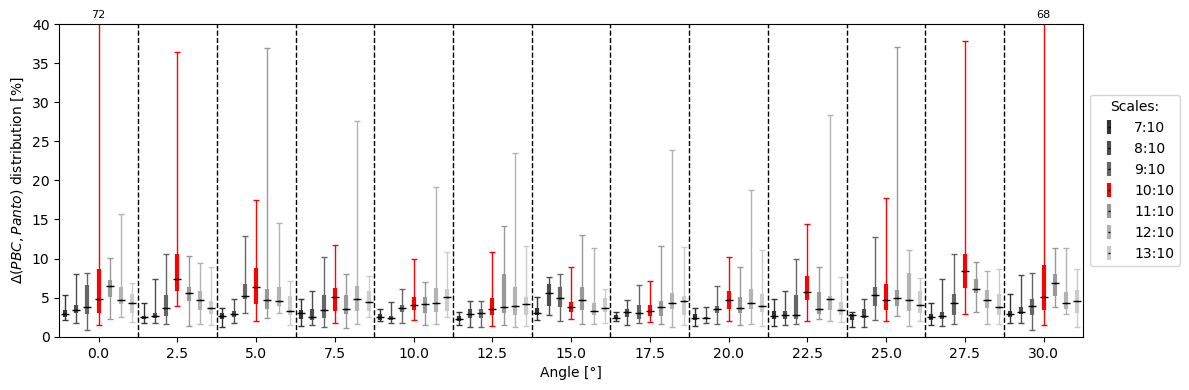

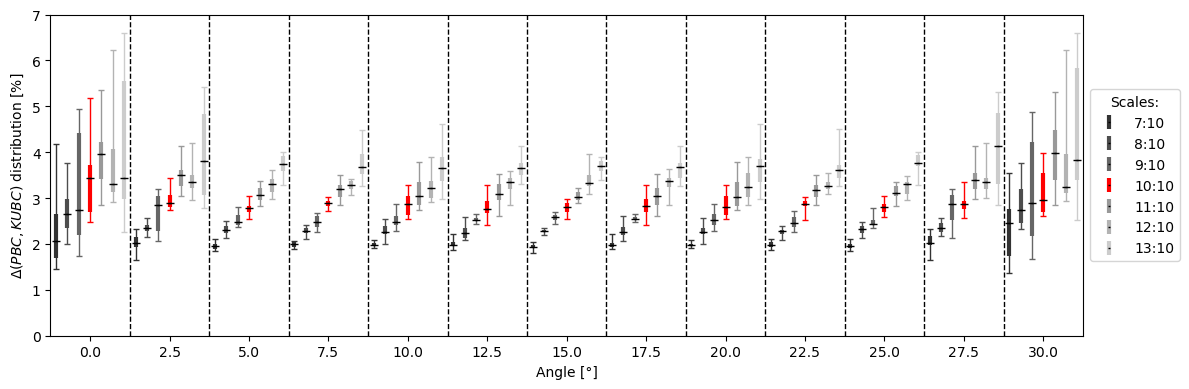

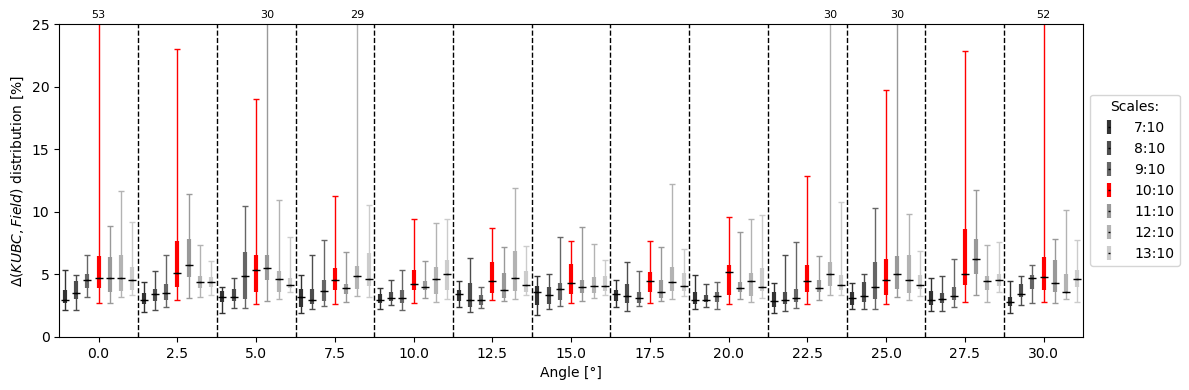

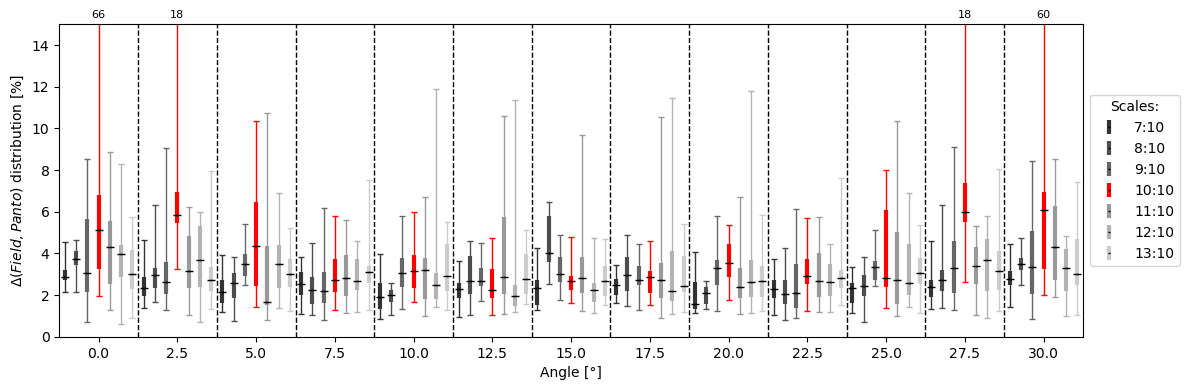

In [29]:
plot_map_theta_size(data, (13, 7, 7, 7),eoi=(0,3), angle_max=30.0, ymax=40,error=r'$\Delta (PBC,Panto)$', loop=False)
plt.savefig('images/map_honey_eoi_03.pdf')
plot_map_theta_size(data, (13, 7, 7, 7),eoi=(0,1), angle_max=30.0, ymax=7,error=r'$\Delta (PBC,KUBC)$', loop=False)
plt.savefig('images/map_honey_eoi_01.pdf')
plot_map_theta_size(data, (13, 7, 7, 7),eoi=(1,2), angle_max=30.0, ymax=25,error=r'$\Delta (KUBC,Field)$', loop=False)
plt.savefig('images/map_honey_eoi_12.pdf')
plot_map_theta_size(data, (13, 7, 7, 7),eoi=(2,3), angle_max=30.0, ymax=15,error=r'$\Delta (Field,Panto)$', loop=False)
plt.savefig('images/map_honey_eoi_23.pdf')

print(data['honey_7_5_4_5'].get_error((0,3)))

On peut remarquer les points suivants:
- Le motif 10/10 est clairement à eviter car il présente des erreurs très importante
- Le meilleur motif est le 7/10 et le 13/10 est meilleur que le 10/10.
- Les minimums sont très similaire dans tous les cas et la meilleur configuation n'est pas atteinte avec un 7/10 (mais un 9/10)

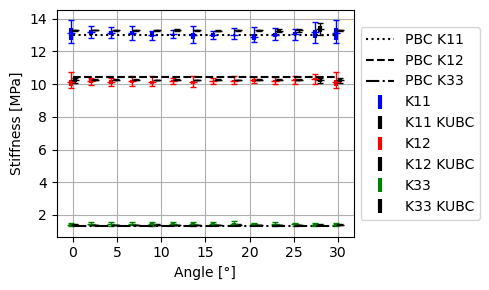

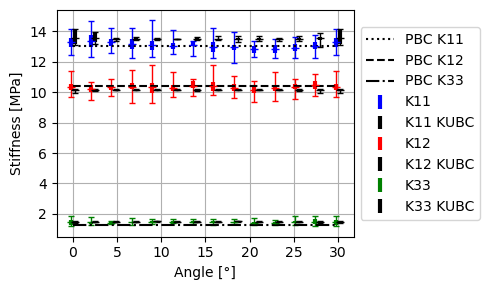

In [30]:
data_scale_7 = get_tests_by_test_id(data, index=1, target='7')
data_scale_8 = get_tests_by_test_id(data, index=1, target='8')
data_scale_9 = get_tests_by_test_id(data, index=1, target='9')
data_scale_10 = get_tests_by_test_id(data, index=1, target='10')
data_scale_11 = get_tests_by_test_id(data, index=1, target='11')
data_scale_12 = get_tests_by_test_id(data, index=1, target='12')
data_scale_13 = get_tests_by_test_id(data, index=1, target='13')
plot_coef_matrix_per_angle(data_scale_7, (13, 7, 7, 7), angle_max=30.0)
plt.savefig('images/map_honey_coef_7.pdf')
plot_coef_matrix_per_angle(data_scale_13, (13, 7, 7, 7), angle_max=30.0)
plt.savefig('images/map_honey_coef_13.pdf')


In [31]:
def get_tests_by_test_id2(data, index: int, target: list[str]) -> dict[Test]:
    """ return a dict of test based on the test_id with _ split"""
    new_dict = {}
    for key in data:
        if key.split('_')[index] in target:
            new_dict |= {key: data[key]}
    return new_dict

coefs=((0,0),(1,0),(2,2))


data_no_CC=get_tests_by_test_id2(data_scale_7, index=2, target=[str(i) for i  in ['3']])
for coef in coefs:
    K33_dev_mean_noCC=0.0
    for _,test in data_no_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_noCC += abs(k33-k33_pbc)
    K33_dev_mean_noCC=K33_dev_mean_noCC/len(data_no_CC)



    print(f'Ecart absolu {coef=}: \nNo CC: {K33_dev_mean_noCC:.2f}')

print(np.array(test.K_plane_stress_PBC))

Ecart absolu coef=(0, 0): 
No CC: 0.18
Ecart absolu coef=(1, 0): 
No CC: 0.20
Ecart absolu coef=(2, 2): 
No CC: 0.14
[[ 1.30166807e+01  1.04133083e+01 -4.74156829e-05]
 [ 1.04133083e+01  1.30170165e+01 -3.80007024e-06]
 [-4.74156831e-05 -3.80006540e-06  1.30185353e+00]]


- En terme de coefficient, le 13/10 présente un eplus gande variabilité
- On remarque surtout que pour le 7/10, l'erreur PBC KUBC  discret est de l'ordre de grandeur de l'erreur KUBC theorique - PBC.

## Erreur liée au support manquant

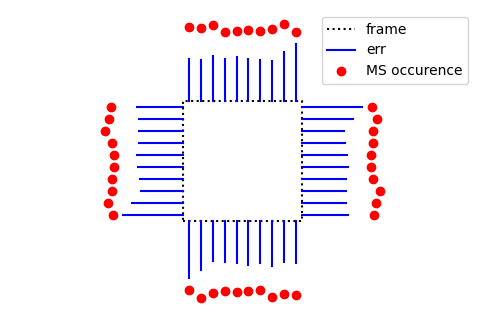

In [32]:
def plot_err_per_MS(data: dict[Test], eoi: tuple = (0, 3), factor: tuple = (20,20)):
    plt.figure()
    plt.axis('equal')
    plt.plot([], [], 'k:', label='frame')
    plt.plot([], [], 'b', label='err')
    plt.plot([], [], 'ro', label='MS occurence')
    plt.legend()
    # * plot the square shape of the machine
    plt.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], 'k:')
    mean_err = np.zeros((4, 10))
    counter_err = np.zeros((4, 10))
    for _, test in data.items():
        mean_err = mean_err+test.get_error(eoi)*test.get_MS()
        counter_err = counter_err+test.get_MS()
    mean_err = mean_err/counter_err
    mean_err=1*mean_err/np.max(mean_err)
    counter_err = counter_err/len(data)
    counter_err=1.3*counter_err/np.max(counter_err)
    for cote in range(4):
        for cyl in range(10):
            if cote % 2 == 0:
                plt.plot([-0.9+cyl/5]*2, [-1+cote, (-1+cote)
                                          * (1+mean_err[cote, cyl])], 'b')
                plt.plot([-0.9+cyl/5], [(-1+cote) *
                                        (1+counter_err[cote, cyl])], 'ro')
            else:
                plt.plot([2-cote, (2-cote)*(1+mean_err[cote, cyl])],
                         [-0.9+cyl/5]*2, 'b')
                plt.plot([(2-cote)*(1+counter_err[cote, cyl])],
                         [-0.9+cyl/5], 'ro')
    
    plt.axis('off')
    plt.show()


plot_err_per_MS(data)


On remarque que tous les cylindres ont la même chance d'être absent mais que ceux dans les coins haut droit et bas gauche entrainnent une erreur légèrement supérieure en moyenne

data


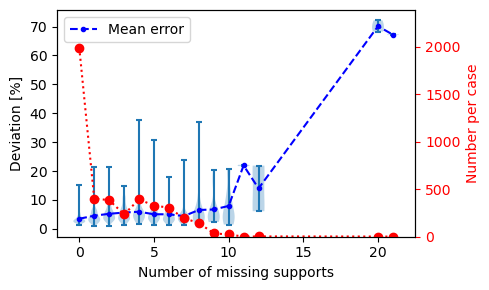

In [33]:

def err_per_number_of_ms(data: dict[Test], eoi:tuple=(0,3), step:float=0.9, width:float=0.1) -> None:
    x_scatter, y_scatter = [], []
    for _, test in data.items():
        err = test.get_error(eoi)
        number_missing_support = sum([len(i) for i in test.skipped_cyl])
        x_scatter.append(number_missing_support)
        y_scatter.append(err)

    X_sorted, Y_sorted = (list(t) for t in zip(*sorted(zip(x_scatter, y_scatter))))
    old = X_sorted[0]
    X_bulk, Y_bulk, number_per_x= [old], [[]], []
    counter=0
    for x, y in zip(X_sorted, Y_sorted):
        if x<old+step:
            Y_bulk[-1].append(y)
            counter+=1
            continue
        number_per_x.append(counter)
        X_bulk.append(x)
        Y_bulk.append([y])
        old = x
        counter=0
    number_per_x.append(counter)
    y_mean = []
    for y in Y_bulk:
        y_mean.append(np.mean(np.array(y)))
    y_mean = np.array(y_mean)

    plt.violinplot(Y_bulk, X_bulk,widths=width,
                   showmeans=False, showmedians=False, showextrema=True)
    plt.plot(X_bulk, y_mean, '.b--', label='Mean error')
    plt.xlabel(f'Number of missing supports')
    # plt.ylim(top=20)
    plt.ylabel('Deviation [%]')
    plt.legend()
    ax2=plt.twinx()
    ax2.set_ylim(bottom=0, top=1.2*np.max(number_per_x))
    ax2.plot(X_bulk, number_per_x, 'ro:')
    ax2.set_ylabel('Number per case', color='r')
    ax2.tick_params(axis='y', colors='red')


# to_plot=['data', 'data_scale_7','data_scale_8', 'data_scale_9', 'data_scale_10', 
#          'data_scale_11', 'data_scale_12', 'data_scale_13']
to_plot=['data']

for i in to_plot:
    print(i)
    plt.figure(figsize=(5,3))
    err_per_number_of_ms(eval(i), width=0.8)
plt.tight_layout()
plt.savefig('images/MS_nida.pdf')

- La perte ne 1 ou plusieur cylindre n'entraine pas nécéssairement une augmentation significative de l'erreur. Ce n'est pas un critère suffisant. C'est certe pertinent quand on considère tous les tests mais pour les 7 et 8/10 il ne manque aucun cylindre. 
- L'etude de l'erreur la le nombre manquant de cylindre ne semble donc pas pertinante.

honey_7_2_0_0
1.2692148166686783
174288


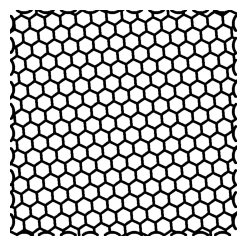

In [34]:

best_t=get_best_test(data_scale_7,number=1)
# %matplotlib qt 
for t in best_t:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()


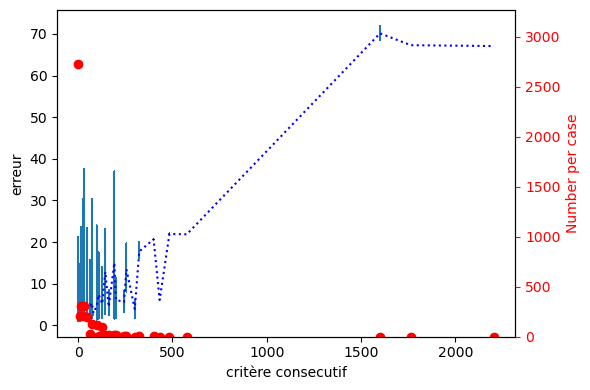

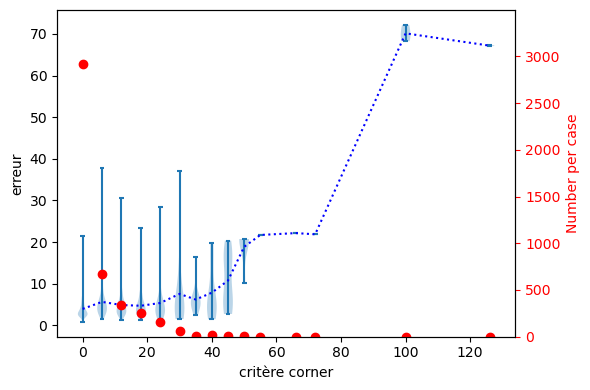

In [35]:

eoi=(0,3)

err=[]
criteria=[]
for _,test in data.items():
    err.append(test.get_error(eoi))
    criteria.append(get_max_MS_consecutive(test)*test.get_number_ms())

plot_box2(criteria,err, step=5, ylabel=f'critère consecutif', width=3)
    

def get_mean_MS_worse_corner2(test: Test) -> float:
    mat_MS = test.get_MS()
    mat_MS_corner = test.get_MS_corner()
    return np.max(2*np.sum(mat_MS_corner, axis=1))*test.get_number_ms()

err=[]
criteria=[]
for _,test in data.items():
    err.append(test.get_error(eoi))
    criteria.append(get_mean_MS_worse_corner2(test))

plot_box2(criteria,err, step=5, ylabel=f'critère corner', width=3)

Ces différents critères ne semble pas apporter d'information significative. D'autant plus que la base de données contient également les essais 7 et 8/10 qui n'ont jamais de support manquant.

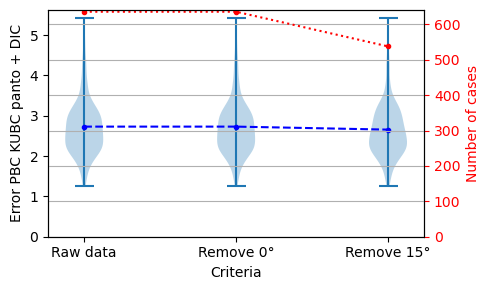

WORSE
honey_7_12_0_2
5.414059095695093
196217
honey_7_12_3_1
5.397128720278193
130096
BEST
honey_7_2_0_0
1.2692148166686783
174288
honey_7_10_0_0
1.2816794138565475
42939


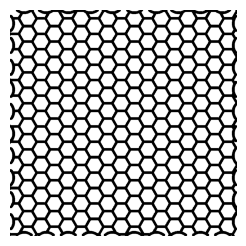

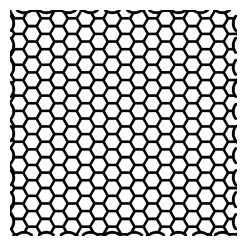

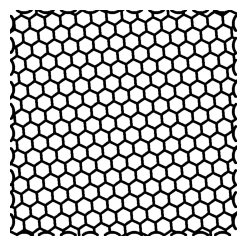

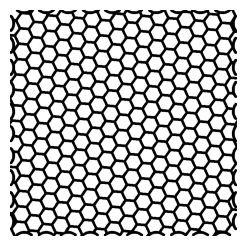

In [36]:

data_raw = data_scale_7
data_list = [[], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[1] not in ['7']:  
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[2] in ['0','6',]:
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))
    last_tests_dict |= {test_id:test}


plt.figure(figsize=(5,3))
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)

plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--')

plt.xticks(range(len(data_list)), ['Raw data', 'Remove 0°', 'Remove 15°'])
plt.ylim(bottom=0.0)
plt.ylabel('Error PBC KUBC panto + DIC')
plt.xlabel('Criteria')
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)
plt.grid()
plt.tight_layout()
plt.savefig('images/MS_nida_selection.pdf')
plt.show()

print('WORSE')
wb_tests=get_worse_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()

print('BEST')
wb_tests=get_best_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()

En observant les meilleurs et pires test, ont peut en déduire des régles à l'oeil afin de limiter les min et max. On remarque ici qu'enlever les orientation 0 et 30 permet ici de réduire le max et même d'améliorer la moyenne.

## Effet des CC

Etude de l'effet des CC sur le NIDA taille 7/10

Lecture des données réalisée en 0.22870s


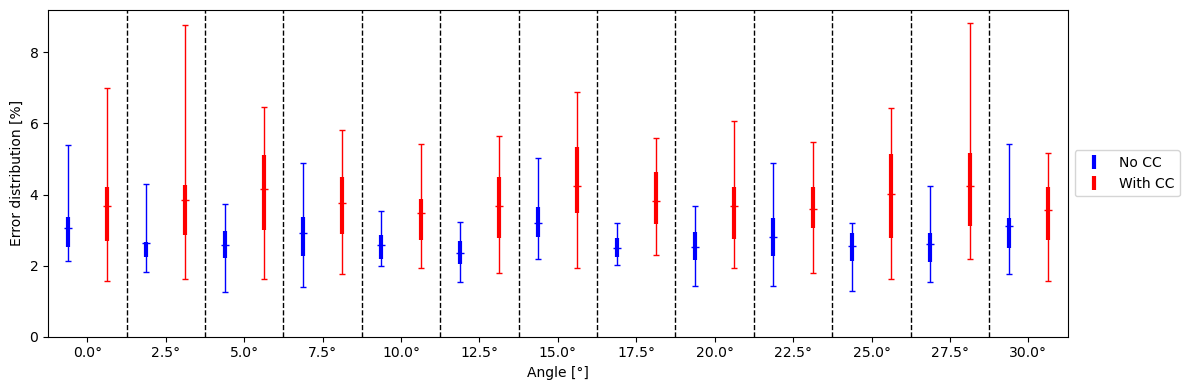

[2.75373111 3.81587842]


In [37]:
data_no_CC = data_scale_7
data_CC = get_bulk_data(read_data_from_campaigns(['campagne_honey_CC']))

bulk_data = data_no_CC | data_CC


N_theta, N_type, N_tx, N_ty = (13, 2, 7, 7)
EOI = (0, 3)

error_per_angle = np.empty((N_theta+1, N_type, N_tx, N_ty))
error_per_angle[:] = np.nan
for test_id, test in bulk_data.items():
    scale, angle, idx, idy = tuple(map(int, test_id.split('_')[1:]))
    if test_id.split('_')[0][-1]=='C':
        cc=1
    else:
        cc=0

    error_per_angle[angle, cc, idx,
                    idy] = test.get_error(EOI)
    if angle == 0:
        error_per_angle[-1, cc, idx,
                        idy] = test.get_error(EOI)

error_per_angle_mean = np.nanmean(error_per_angle, axis=(2, 3))
error_per_angle_q1 = np.nanquantile(error_per_angle, 0.25, axis=(2, 3))
error_per_angle_q2 = np.nanquantile(error_per_angle, 0.75, axis=(2, 3))
error_per_angle_min = np.nanmin(error_per_angle, axis=(2, 3))
error_per_angle_max = np.nanmax(error_per_angle, axis=(2, 3))

plt.figure(figsize=(12, 4))
x = np.linspace(0, N_theta, N_theta+1)-0.5+1/N_type/2
col = ['b', 'r', 'r', 'm', 'k', 'c', 'y']
leg = ['No CC', 'With CC']

for scale in range(N_type):
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_q1[:, scale], error_per_angle_q2[:, scale] - error_per_angle_mean[:, scale]],
                 fmt=col[scale]+'_', lw=3, ms=1, label=f'{leg[scale]}')
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_min[:, scale], error_per_angle_max[:, scale] - error_per_angle_mean[:, scale]],
                 fmt='_'+col[scale], ecolor=col[scale], lw=1, capsize=2)
    for i, m in enumerate(error_per_angle_max[:, scale]):
        if m > 30.0:
            plt.text(x[i]+scale/N_type,
                     30.0, f'{m:.0f}', ha='center', fontsize=8)

for i in range(12):
    plt.axvline(x=i+0.5, color='k', ls='--', lw=1.0)

plt.ylim(bottom=0)
plt.xlim((-0.5, 12.5))
plt.xticks(range(13), [f'{2.5*i}°' for i in range(13)])
plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Angle [°]')
plt.ylabel(f'Error distribution [%]')
plt.tight_layout()
plt.show()

print(np.mean(error_per_angle_mean, axis=0))

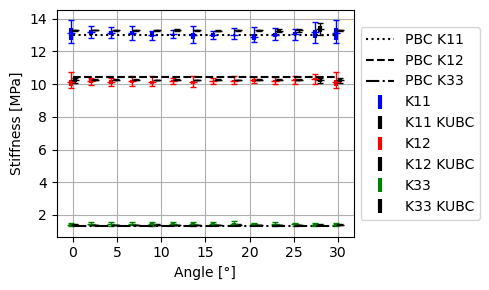

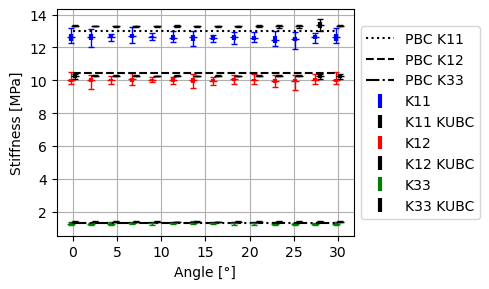

In [38]:
plot_coef_matrix_per_angle(data_scale_7, (13, 7, 7, 7), angle_max=30.0)
plot_coef_matrix_per_angle(data_CC, (13, 7, 7, 7), angle_max=30.0)

Les CC semble surtout amélioirer la mesure du coef K33 de la matrice de rigidité. Dans la suite on quantifie l'amélioration moyenne de l'erreur.

In [45]:
coefs=((0,0),(1,0),(2,2))

data_no_CC=data_scale_7
for coef in coefs:
    K33_dev_mean_noCC=0.0
    for _,test in data_no_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_noCC += abs(k33-k33_pbc)/k33_pbc
    K33_dev_mean_noCC=K33_dev_mean_noCC/len(data_no_CC)*100



    print(f'Erreur moyenne [%] {coef=}: \nNo CC: {K33_dev_mean_noCC:.1f}')

print(np.array(test.K_plane_stress_PBC))

Erreur moyenne [%] coef=(0, 0): 
No CC: 1.5
Erreur moyenne [%] coef=(1, 0): 
No CC: 2.3
Erreur moyenne [%] coef=(2, 2): 
No CC: 10.3
[[ 1.30168296e+01  1.04132448e+01 -1.19161260e-04]
 [ 1.04132448e+01  1.30169946e+01 -3.57750781e-05]
 [-1.19161261e-04 -3.57750744e-05  1.30179003e+00]]


In [46]:
coefs=((0,0),(1,0),(2,2))
for coef in coefs:
    K33_dev_mean_noCC=0.0
    for _,test in data_no_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_noCC += abs(k33-k33_pbc)/k33_pbc
    K33_dev_mean_noCC=K33_dev_mean_noCC/len(data_no_CC)*100

    K33_dev_mean_CC=0.0
    for _,test in data_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_CC += abs(k33-k33_pbc)/k33_pbc
    K33_dev_mean_CC=K33_dev_mean_CC/len(data_CC)*100

    print(f'Erreur moyenne [%] {coef=}: \nNo CC: {K33_dev_mean_noCC:.1f}\nCC:    {K33_dev_mean_CC:.1f}')

Erreur moyenne [%] coef=(0, 0): 
No CC: 1.5
CC:    3.2
Erreur moyenne [%] coef=(1, 0): 
No CC: 2.3
CC:    3.9
Erreur moyenne [%] coef=(2, 2): 
No CC: 10.3
CC:    2.9


La découpe a un effet (en moyenne) très bénéfique sur la mesure. L'erreur sur le coef K33 passe de 11 à 5%!

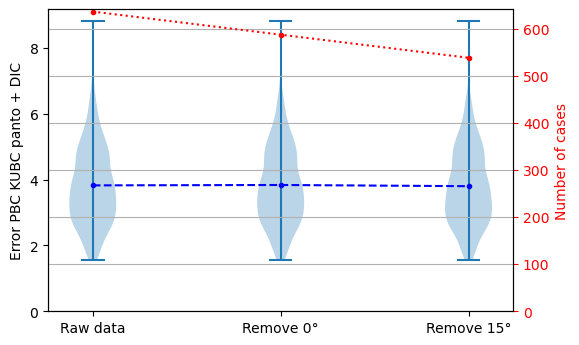

In [41]:

data_raw = data_CC
data_list = [[], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[2] in ['0']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[2] in ['6']:
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))
    last_tests_dict |= {test_id:test}


plt.figure()
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)

plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--')

plt.xticks(range(len(data_list)), ['Raw data', 'Remove 0°', 'Remove 15°'])
plt.ylim(bottom=0.0)
plt.ylabel('Error PBC KUBC panto + DIC')
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)
plt.grid()
plt.show()

# print('WORSE')
# wb_tests=get_worse_test(last_tests_dict,number=1)
# for t in wb_tests:
#     print(t.test_id)
#     print(t.get_error((0,3)))
#     t.show_geo()

# print('BEST')
# wb_tests=get_best_test(last_tests_dict,number=1)
# for t in wb_tests:
#     print(t.test_id)
#     print(t.get_error((0,3)))
#     t.show_geo()

Contrairement au cas sans découpe, enlever les orientation 0 et30° n'améliore pas le max ni la moyenne. On cherche à déterminer dans ce qui suit, pourquoi dans certain cas la découpe améliore la mésure, et dans d'autre non.

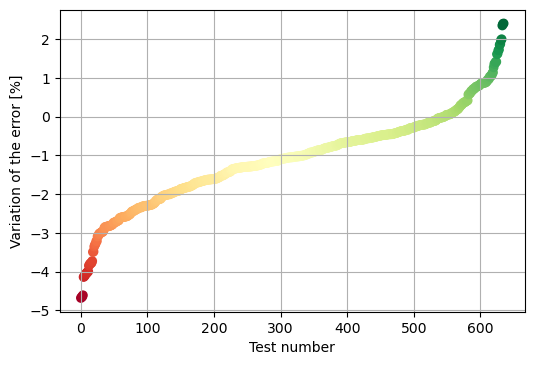

547
Amélioration moyenne : -1.0958317281926409
Tests pour qui ca a le mieux marché
honeyCC_7_2_6_4 avec un évolution de 1.6227518343506615


<Figure size 700x700 with 0 Axes>

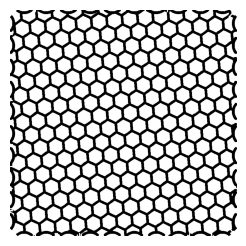

honeyCC_7_12_4_1 avec un évolution de 1.7068088128670516


<Figure size 700x700 with 0 Axes>

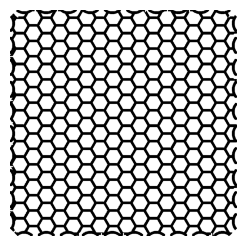

honeyCC_7_12_2_5 avec un évolution de 1.7238722096993158


<Figure size 700x700 with 0 Axes>

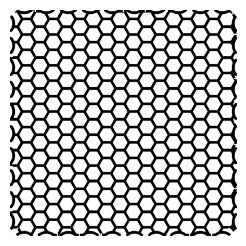

honeyCC_7_0_2_1 avec un évolution de 1.848025199500769


<Figure size 700x700 with 0 Axes>

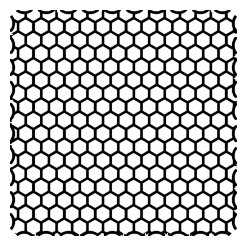

honeyCC_7_0_4_5 avec un évolution de 1.8725328581644867


<Figure size 700x700 with 0 Axes>

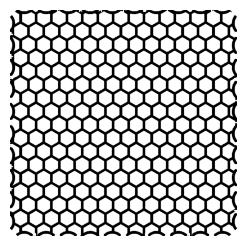

honeyCC_7_9_5_0 avec un évolution de 1.9707636254271033


<Figure size 700x700 with 0 Axes>

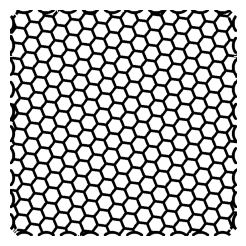

honeyCC_7_9_1_6 avec un évolution de 1.9935730958716302


<Figure size 700x700 with 0 Axes>

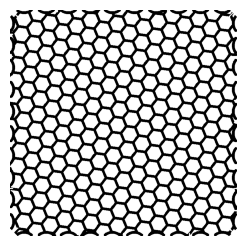

honeyCC_7_9_6_0 avec un évolution de 2.3476367071974225


<Figure size 700x700 with 0 Axes>

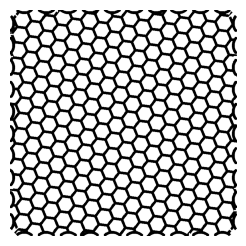

honeyCC_7_9_0_6 avec un évolution de 2.3895576534253986


<Figure size 700x700 with 0 Axes>

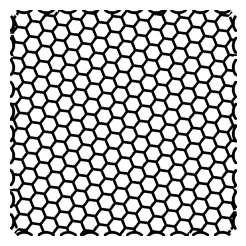

honeyCC_7_3_3_3 avec un évolution de 2.4004014193595626


<Figure size 700x700 with 0 Axes>

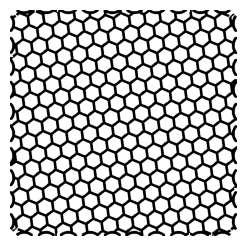

Tests pour qui ca a le moins bien marché
honeyCC_7_11_4_4 avec un évolution de -4.680635177553156


<Figure size 700x700 with 0 Axes>

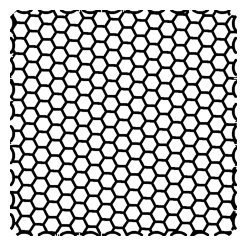

honeyCC_7_11_2_2 avec un évolution de -4.656257450094631


<Figure size 700x700 with 0 Axes>

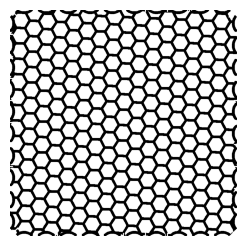

honeyCC_7_1_2_6 avec un évolution de -4.649669369284634


<Figure size 700x700 with 0 Axes>

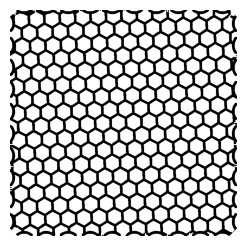

honeyCC_7_1_4_0 avec un évolution de -4.609743501388366


<Figure size 700x700 with 0 Axes>

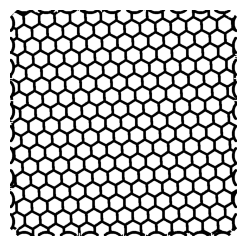

honeyCC_7_1_3_2 avec un évolution de -4.139331780715899


<Figure size 700x700 with 0 Axes>

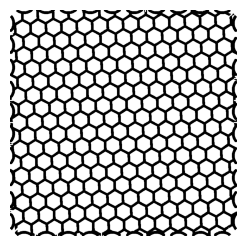

honeyCC_7_2_1_4 avec un évolution de -4.123835774362214


<Figure size 700x700 with 0 Axes>

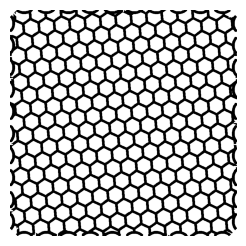

honeyCC_7_2_5_2 avec un évolution de -4.100181020250193


<Figure size 700x700 with 0 Axes>

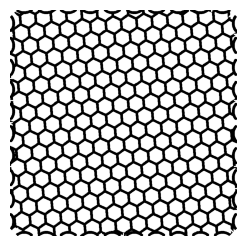

honeyCC_7_1_3_4 avec un évolution de -4.067272001187442


<Figure size 700x700 with 0 Axes>

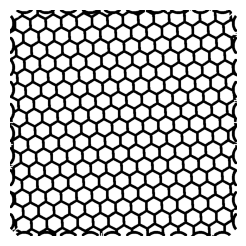

honeyCC_7_11_4_1 avec un évolution de -4.040661451778748


<Figure size 700x700 with 0 Axes>

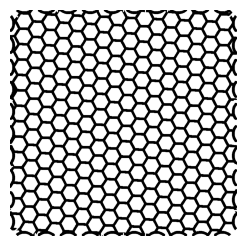

honeyCC_7_0_3_6 avec un évolution de -4.038150403011052


<Figure size 700x700 with 0 Axes>

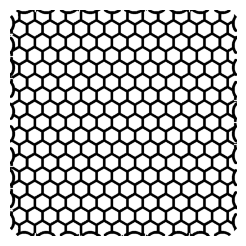

In [42]:
""" Understand whyl in some cases the CC is better and sometime no"""
# data_CC
# data_no_CC
changes=[]
names=[]
eoi=(0,3)
for test_id,test in data_CC.items():
    changes.append(-test.get_error(eoi)+data_no_CC[test_id[:5]+test_id[7:]].get_error(eoi))
    names.append(test_id)


changes, names=[list(i) for i in zip(*sorted(zip(changes, names)))]

plt.scatter(range(len(changes)), changes,c=changes, cmap='RdYlGn', vmin=min([min(changes),-max(changes)]))
plt.grid()
plt.xlabel('Test number')
plt.ylabel('Variation of the error [%]')
plt.show()

j=0
while changes[j]<0:
    j+=1
print(j)

N=10
print(f'Amélioration moyenne : {np.mean(np.asarray(changes))}')
print('Tests pour qui ca a le mieux marché')
for name, val in zip(names[-N:],changes[-N:]):
    print(f'{name} avec un évolution de {val}')
    plt.figure(figsize=(7,7))
    data_CC[name].show_geo()
    plt.show()

print('Tests pour qui ca a le moins bien marché')
for name, val in zip(names[:N],changes[:N]):
    print(f'{name} avec un évolution de {val}')
    plt.figure(figsize=(7,7))
    data_CC[name].show_geo()
    plt.show()



On remarque que dans environ 150 cas sur 600, la découpe dans les coins augmente l'erreur. En observant les cas, on remarque que cela intervient lorsque la déoupe entaille une barre dans la longueur. Ces cas pourront être éliminés à la main.

# Etude de l'effet lié à la libre rotation des cylindres

Lecture des données réalisée en 0.67153s


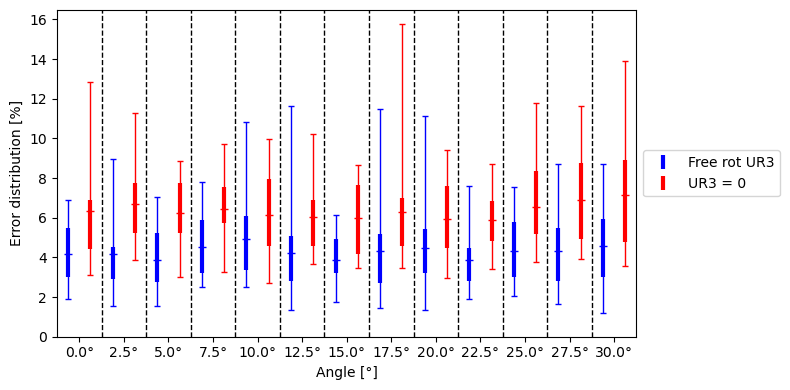

[4.2682406  6.35735098]


In [43]:
data_scale_13_UR3 = get_bulk_data(read_data_from_campaigns(['campagne_honey_UR3']))


bulk_data = data_scale_13 | data_scale_13_UR3


N_theta, N_type, N_tx, N_ty = (13, 2, 7, 7)
EOI = (0, 3)

error_per_angle = np.empty((N_theta+1, N_type, N_tx, N_ty))
error_per_angle[:] = np.nan
for test_id, test in bulk_data.items():
    scale, angle, idx, idy = tuple(map(int, test_id.split('_')[1:]))
    
    if test_id.split('_')[0][-1]=='3':
        cc=1
    else:
        cc=0

    error_per_angle[angle, cc, idx,
                    idy] = test.get_error(EOI)
    if angle == 0:
        error_per_angle[-1, cc, idx,
                        idy] = test.get_error(EOI)

error_per_angle_mean = np.nanmean(error_per_angle, axis=(2, 3))
error_per_angle_q1 = np.nanquantile(error_per_angle, 0.25, axis=(2, 3))
error_per_angle_q2 = np.nanquantile(error_per_angle, 0.75, axis=(2, 3))
error_per_angle_min = np.nanmin(error_per_angle, axis=(2, 3))
error_per_angle_max = np.nanmax(error_per_angle, axis=(2, 3))

plt.figure(figsize=(8, 4))
x = np.linspace(0, N_theta, N_theta+1)-0.5+1/N_type/2
col = ['b', 'r', 'r', 'm', 'k', 'c', 'y']
leg = ['Free rot UR3', 'UR3 = 0']

for scale in range(N_type):
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_q1[:, scale], error_per_angle_q2[:, scale] - error_per_angle_mean[:, scale]],
                 fmt=col[scale]+'_', lw=3, ms=1, label=f'{leg[scale]}')
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_min[:, scale], error_per_angle_max[:, scale] - error_per_angle_mean[:, scale]],
                 fmt='_'+col[scale], ecolor=col[scale], lw=1, capsize=2)
    for i, m in enumerate(error_per_angle_max[:, scale]):
        if m > 30.0:
            plt.text(x[i]+scale/N_type,
                     30.0, f'{m:.0f}', ha='center', fontsize=8)

for i in range(12):
    plt.axvline(x=i+0.5, color='k', ls='--', lw=1.0)

plt.ylim(bottom=0)
plt.xlim((-0.5, 12.5))
plt.xticks(range(13), [f'{2.5*i}°' for i in range(13)])
plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Angle [°]')
plt.ylabel(f'Error distribution [%]')
plt.tight_layout()
plt.show()

print(np.mean(error_per_angle_mean, axis=0))

La libre rotation des cylindres est très importante lorsque le motif est grand car chaque support est connecté via (en générale) à une unique poutre (-> effet de l'angle d'incidence et de la position).
Il serait peut-être pertinent de refaire ce mapping avec UR3 bloqué avec le motif 7/10 pour montrer que la liason support motif est bien la composante décisive pour améliorer l'erreur dans le cas de grands motifs.

# Regles de conception

- Choisir un motif de petite taille 
- Ne pas aligner le motif sur le cadre (eg 0° ou 30° pour le nida)
- Faire une découpe dans les coins mais ne pas couper une barre dans sa longueur
- quitte à perdre un cylindre, il vaut mieux ne pas le perdre dans le coins en haut à droite et en  bas à gauche
  

In [44]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 

campagnes = ['campagne_honey']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))
data_scale_13 = get_tests_by_test_id(data, index=1, target='13')
data_scale_13_UR3 = get_bulk_data(read_data_from_campaigns(['campagne_honey_UR3_S13']))


fr_err_list=[]
for _,test in data_scale_13.items():
    fr_err_list.append(test.get_error((0,3)))
rb_err_list=[]
for _,test in data_scale_13_UR3.items():
    rb_err_list.append(test.get_error((0,3)))
plt.figure(figsize=(4,3))
bp = plt.boxplot([fr_err_list,rb_err_list], patch_artist=True, whis=(0,100),medianprops={'color':'k'},boxprops={'fill':False})

plt.ylim(bottom=0.0)
plt.xticks(range(1,3), ['Free rotation', 'Rotation blocked'])
plt.ylabel(r'$r(\mathcal{K}_\mathcal{PBC},\mathcal{K}_\mathcal{P})$ [%]')



Lecture des données réalisée en 1.95831s


FileNotFoundError: [Errno 2] No such file or directory: '/data0/usrtmp/valmalette/abakubc/campagne_honey_UR3_S13.csv'